# 3b. Word2vec codon embeddings (skip-gram with negative sampling)

Notebook 03a described each codon by raw neighbour counts. Here we **learn** a short dense vector per codon
type with the skip-gram objective of word2vec, written by hand in NumPy (as in Zombienella 03b):

- every codon (the *target*) is paired with each codon within ±k positions (its *contexts*);
- a logistic model learns to tell those observed pairs from random *negative* pairs;
- the target vectors that make this possible are the embeddings.

Three corpora:

| Corpus | Content | Experiment |
|---|---|---|
| `dna` | the 400 genomes, pathway gene order | the main embeddings |
| `shuffled` | the same genomes with the genes in random order | control for pathway order (S5) |
| `mixed` | the genomes **plus** their transcripts, with no Z/V normalisation | do `ZWX` and `VWX` converge? (S6) |

Each corpus is trained with half-windows ±1 and ±9 (±9 covers the distance from one gene's terminator to the
next gene's marker) and dimensions 2, 3 and 8: 18 runs.

The predictions S1–S6 of design-spec §7 are then tested with criteria **fixed before training**, and reported
as they came out.

> **Proximity means similar contexts, not similar meaning.**

*Run from `03-static/`.*

In [1]:
import sys, os, json, inspect, time
from datetime import datetime, timezone
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

sys.path.insert(0, "..")
import protocell_lang as L

# ------------------------------------------------------------
# Configuration (design-spec §4.4)
# ------------------------------------------------------------
SEED = 42
HALF_WINDOWS = [1, 9]
DIMENSIONS = [2, 3, 8]
CORPORA = ["dna", "shuffled", "mixed"]

NEGATIVES = 5            # negative samples per positive pair
LEARNING_RATE = 0.025
EPOCHS = 5
BATCH_SIZE = 1024
INIT_STD = 0.1

N_PERMUTATIONS = 1000    # for the prediction baselines

CORPUS_DIR = "../data/corpus"
OUTPUT_FILE = "../data/web/w2v-results.json"
NOTEBOOK = "03-static/03b_word2vec.ipynb"

## The three corpora

A sequence is one genome or one transcript; context windows never cross from one sequence into the next. The
mixed corpus spells RNA codons with V, so a codon containing Z has two surface forms (`ZWX` in DNA, `VWX` in
RNA) that the model sees as **unrelated tokens**.

In [2]:
def read_sequences(path, key):
    frame = pd.read_csv(path).sort_values([key, "position"])
    return [group["codon"].tolist() for _, group in frame.groupby(key)]


dna = read_sequences(f"{CORPUS_DIR}/genome.csv", "genome_id")
shuffled = read_sequences(f"{CORPUS_DIR}/genome-shuffled.csv", "genome_id")
transcripts = read_sequences(f"{CORPUS_DIR}/transcripts.csv", "transcript_id")
corpora = {"dna": dna, "shuffled": shuffled, "mixed": dna + transcripts}


def vocabulary_of(sequences):
    # Canonical order: the 64 DNA codons, then the RNA forms (with V); only tokens that occur.
    seen = {c for s in sequences for c in s}
    order = L.ALL_CODONS + [L.transcribe(c) for c in L.ALL_CODONS if "Z" in c]
    return [c for c in order if c in seen]


vocabularies = {name: vocabulary_of(seqs) for name, seqs in corpora.items()}
for name, seqs in corpora.items():
    print(f"{name:9} {len(seqs):5} sequences, {sum(map(len, seqs)):7} tokens, vocabulary {len(vocabularies[name])}")

dna         400 sequences,   97991 tokens, vocabulary 64
shuffled    400 sequences,   97991 tokens, vocabulary 64
mixed      2000 sequences,  292706 tokens, vocabulary 101


## Target/context pairs

With half-window ±k, each target is paired with the codons at offsets −k … −1 and +1 … +k. These are the
positive examples. The pairs are built one offset at a time, with array slicing.

In [3]:
def build_positive_pairs(sequences, vocabulary, half_window):
    index = {c: i for i, c in enumerate(vocabulary)}
    targets, contexts = [], []
    for sequence in sequences:
        ids = np.array([index[c] for c in sequence])
        for offset in range(-half_window, half_window + 1):
            if offset == 0:
                continue
            positions = np.arange(max(0, -offset), min(len(ids), len(ids) - offset))
            targets.append(ids[positions])
            contexts.append(ids[positions + offset])
    return np.concatenate(targets), np.concatenate(contexts)


for k in HALF_WINDOWS:
    t, c = build_positive_pairs(dna, vocabularies["dna"], k)
    print(f"dna, ±{k}: {len(t):,} positive pairs")

dna, ±1: 195,182 positive pairs
dna, ±9: 1,727,838 positive pairs


## The model

Each codon has two vectors: a **target vector** $w$ (a row of $W$), used when it is the centre codon, and a
**context vector** $u$ (a row of $U$), used when it is in the window. A pair is scored by a dot product and a
sigmoid:

$$P(\text{observed} \mid t, c) = \sigma(w_t \cdot u_c).$$

Observed pairs have label 1. For each of them, $k = 5$ **negative** contexts are drawn from the noise
distribution $P_n(c) \propto \text{count}(c)^{3/4}$ and get label 0; fresh negatives are drawn every epoch.
The loss is the binary cross-entropy

$$\ell = -\,y \log \sigma(s) - (1 - y)\log\big(1 - \sigma(s)\big), \qquad s = w_t \cdot u_c,$$

whose gradient is simply $(\sigma(s) - y)\,u_c$ for $w_t$ and $(\sigma(s) - y)\,w_t$ for $u_c$.

Training is mini-batch SGD: the gradients of the 1,024 samples in a batch are computed from the current
weights and **summed** into $W$ and $U$. Lab A runs exactly the same algorithm in JavaScript.

In [4]:
def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -30, 30)))


def noise_distribution(sequences, vocabulary):
    index = {c: i for i, c in enumerate(vocabulary)}
    counts = np.bincount([index[c] for s in sequences for c in s], minlength=len(vocabulary))
    weights = counts.astype(float) ** 0.75
    return weights / weights.sum()


def add_rows(matrix, rows, deltas):
    # matrix[rows[i]] += deltas[i], summing repeated rows (like np.add.at, but faster).
    for j in range(matrix.shape[1]):
        matrix[:, j] += np.bincount(rows, weights=deltas[:, j], minlength=matrix.shape[0])

In [5]:
def train_skipgram(sequences, vocabulary, half_window, dim, epochs=EPOCHS, learning_rate=LEARNING_RATE,
                   negatives=NEGATIVES, batch_size=BATCH_SIZE, seed=SEED):
    rng = np.random.default_rng(seed)
    V = len(vocabulary)
    W = rng.normal(0, INIT_STD, (V, dim))     # target vectors: the embeddings
    U = rng.normal(0, INIT_STD, (V, dim))     # context vectors

    pos_targets, pos_contexts = build_positive_pairs(sequences, vocabulary, half_window)
    noise = noise_distribution(sequences, vocabulary)
    losses = []

    for epoch in range(epochs):
        # Fresh negatives: `negatives` random contexts for every positive pair.
        neg_targets = np.repeat(pos_targets, negatives)
        neg_contexts = rng.choice(V, size=len(neg_targets), p=noise)
        targets = np.concatenate([pos_targets, neg_targets])
        contexts = np.concatenate([pos_contexts, neg_contexts])
        labels = np.concatenate([np.ones(len(pos_targets)), np.zeros(len(neg_targets))])
        order = rng.permutation(len(targets))
        targets, contexts, labels = targets[order], contexts[order], labels[order]

        total_loss = 0.0
        for start in range(0, len(targets), batch_size):
            t = targets[start:start + batch_size]
            c = contexts[start:start + batch_size]
            y = labels[start:start + batch_size]
            score = np.sum(W[t] * U[c], axis=1)
            # Binary cross-entropy, computed stably: log(1 + e^-s) for y = 1, log(1 + e^s) for y = 0.
            total_loss += np.sum(np.logaddexp(0, -score) * y + np.logaddexp(0, score) * (1 - y))
            error = (sigmoid(score) - y)[:, None]
            grad_W, grad_U = error * U[c], error * W[t]       # both from the current weights
            add_rows(W, t, -learning_rate * grad_W)
            add_rows(U, c, -learning_rate * grad_U)
        losses.append(total_loss / len(targets))

    return W, U, losses

## Train the 18 configurations

Each run has its own seed, derived from `SEED`, so any single run can be reproduced on its own.

In [6]:
models = {}
started = time.time()
for ci, corpus in enumerate(CORPORA):
    for k in HALF_WINDOWS:
        for dim in DIMENSIONS:
            t0 = time.time()
            seed = SEED + 1000 * ci + 10 * k + dim
            W, U, losses = train_skipgram(corpora[corpus], vocabularies[corpus], k, dim, seed=seed)
            models[(corpus, k, dim)] = {"W": W, "U": U, "losses": losses, "seed": seed}
            print(f"{corpus:9} ±{k}  dim {dim}:  loss {losses[0]:.4f} → {losses[-1]:.4f}   ({time.time() - t0:.1f} s)")
print(f"\nTotal training time: {time.time() - started:.0f} s")

dna       ±1  dim 2:  loss 0.4266 → 0.4194   (1.0 s)


dna       ±1  dim 3:  loss 0.4225 → 0.4137   (1.0 s)


dna       ±1  dim 8:  loss 0.4122 → 0.4031   (1.3 s)


dna       ±9  dim 2:  loss 0.4441 → 0.4433   (10.1 s)


dna       ±9  dim 3:  loss 0.4418 → 0.4411   (10.8 s)


dna       ±9  dim 8:  loss 0.4378 → 0.4371   (12.5 s)


... (8 outputs left out)

mixed     ±1  dim 8:  loss 0.3829 → 0.3770   (4.2 s)


mixed     ±9  dim 2:  loss 0.4336 → 0.4332   (30.6 s)


mixed     ±9  dim 3:  loss 0.4296 → 0.4291   (33.8 s)


mixed     ±9  dim 8:  loss 0.4233 → 0.4228   (39.3 s)

Total training time: 187 s


### Loss curves

The epoch loss is the mean cross-entropy over that epoch's positive and negative samples — **training
performance**, measured on the data the model learns from. It shows whether training converged; it says
nothing about what the vectors mean.

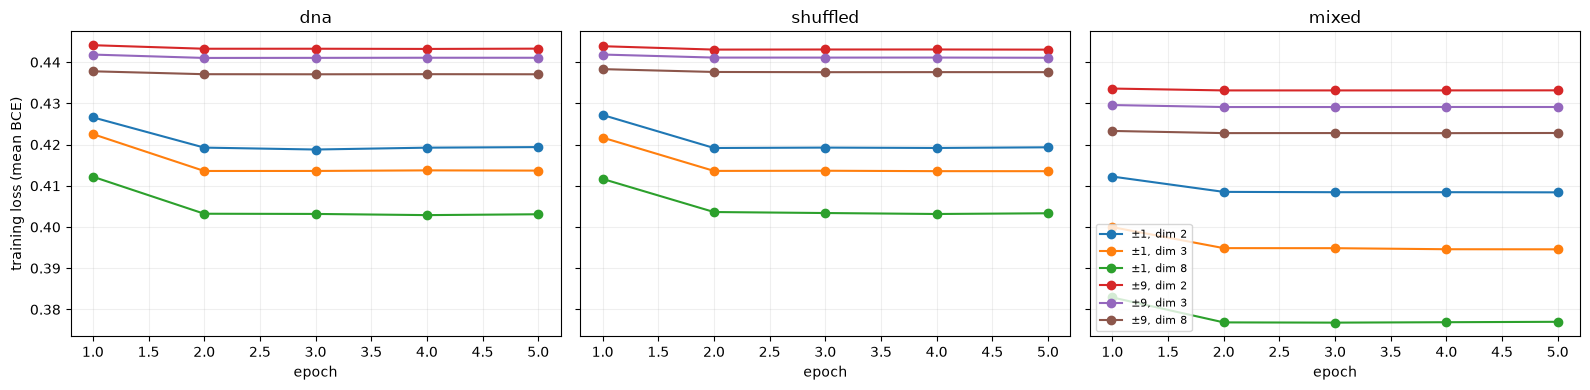

In [7]:
fig, axes = plt.subplots(1, len(CORPORA), figsize=(16, 4), sharey=True)
for ax, corpus in zip(axes, CORPORA):
    for k in HALF_WINDOWS:
        for dim in DIMENSIONS:
            ax.plot(range(1, EPOCHS + 1), models[(corpus, k, dim)]["losses"], marker="o", label=f"±{k}, dim {dim}")
    ax.set_title(corpus)
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("training loss (mean BCE)")
axes[-1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Looking at the embeddings

Colours: codon class (coding / reserved / spacer-only), or, for coding codons, their **preferred gene** (the
gene whose dialect uses them most). Grey lines join synonym pairs. Dimension 8 is drawn through PCA.

As in Zombienella 03b, each run has three views: the target vectors $W$ (the usual embeddings), the context
vectors $U$, and their sum $W + U$.

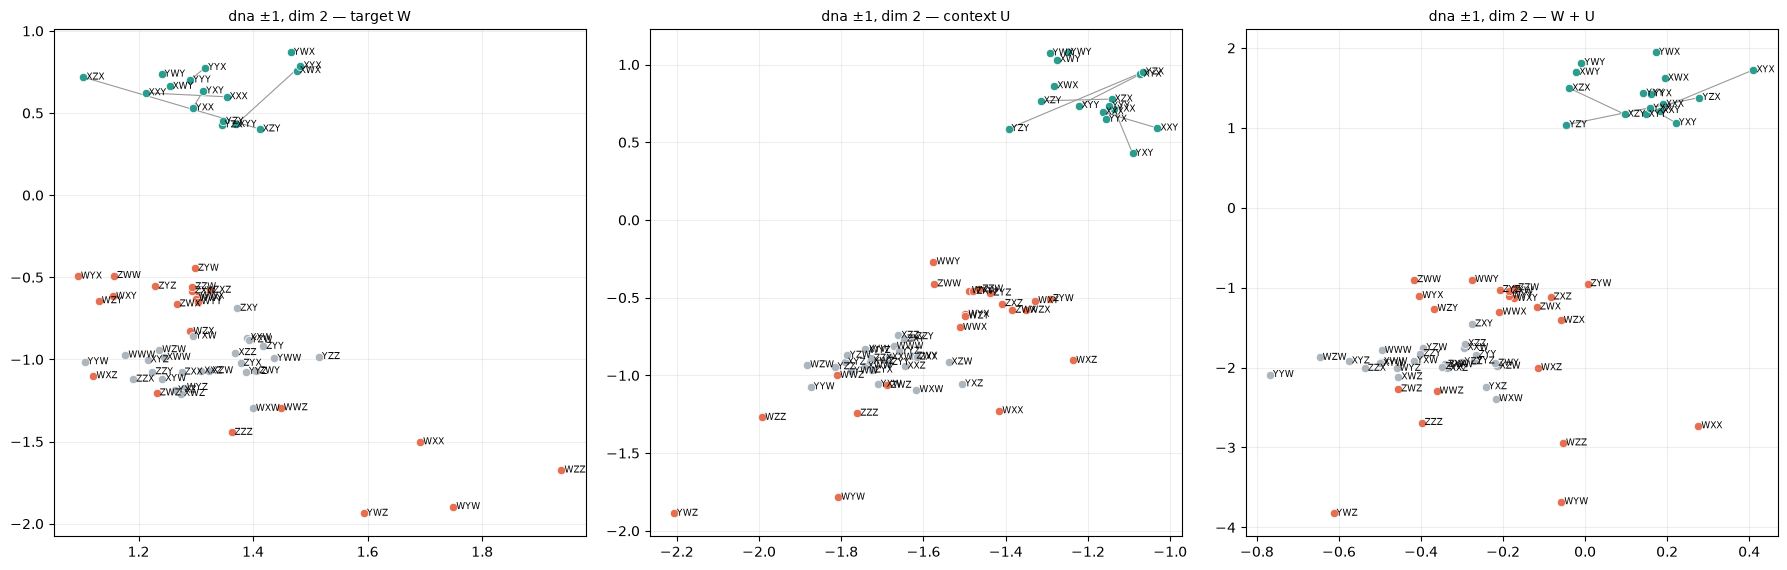

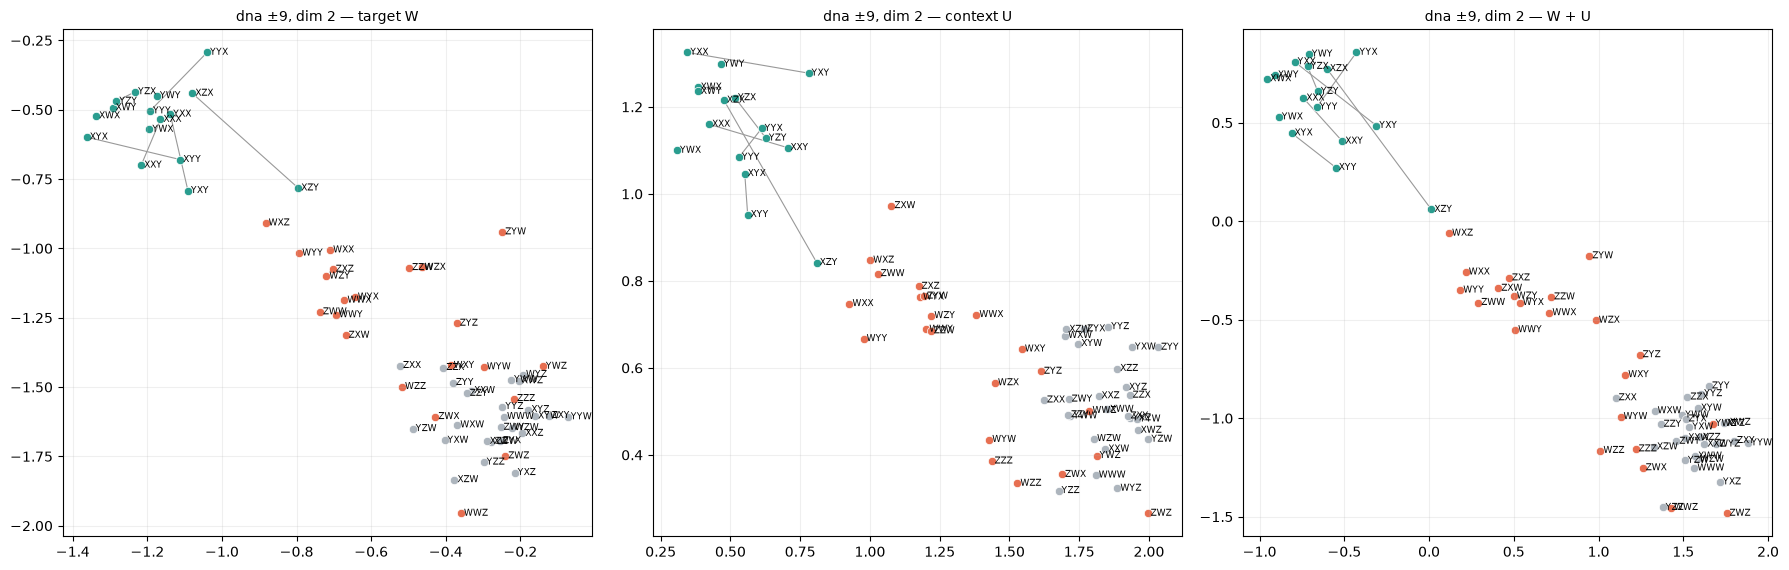

In [8]:
CLASS_COLOURS = {"coding": "#2a9d8f", "reserved": "#e76f51", "spacer-only": "#adb5bd"}
GENE_COLOURS = dict(zip(L.GENE_NAMES, ["#e63946", "#f4a261", "#2a9d8f", "#457b9d", "#9b5de5", "#e9c46a", "#6a994e"]))
SYNONYM_PAIRS = [tuple(L.synonyms(r)) for r in L.RESIDUES if len(L.synonyms(r)) == 2]


def colour_of(codon, colour_by):
    if colour_by == "class":
        return CLASS_COLOURS[L.codon_class(codon)]
    gene = L.preferred_gene(codon)
    return GENE_COLOURS[gene] if gene and L.codon_class(codon) == "coding" else "#dee2e6"


def to_2d(vectors):
    return vectors if vectors.shape[1] == 2 else PCA(n_components=2).fit_transform(vectors)


def plot_embedding(vectors, vocabulary, title, ax, colour_by="class", lines=SYNONYM_PAIRS):
    xy = to_2d(vectors)
    position = {c: xy[i] for i, c in enumerate(vocabulary)}
    for a, b in lines:
        if a in position and b in position:
            ax.plot(*zip(position[a], position[b]), color="#999", lw=0.8, zorder=0)
    for codon, (x, y) in position.items():
        ax.scatter(x, y, s=36, color=colour_of(codon, colour_by), edgecolor="white", linewidth=0.5)
        ax.text(x, y, f" {codon}", fontsize=6.5, va="center")
    ax.set_title(title, fontsize=10)
    ax.grid(alpha=0.2)


for k in HALF_WINDOWS:
    m = models[("dna", k, 2)]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.8))
    for ax, (view, vectors) in zip(axes, [("target W", m["W"]), ("context U", m["U"]), ("W + U", m["W"] + m["U"])]):
        plot_embedding(vectors, vocabularies["dna"], f"dna ±{k}, dim 2 — {view}", ax)
    fig.tight_layout()
    plt.show()

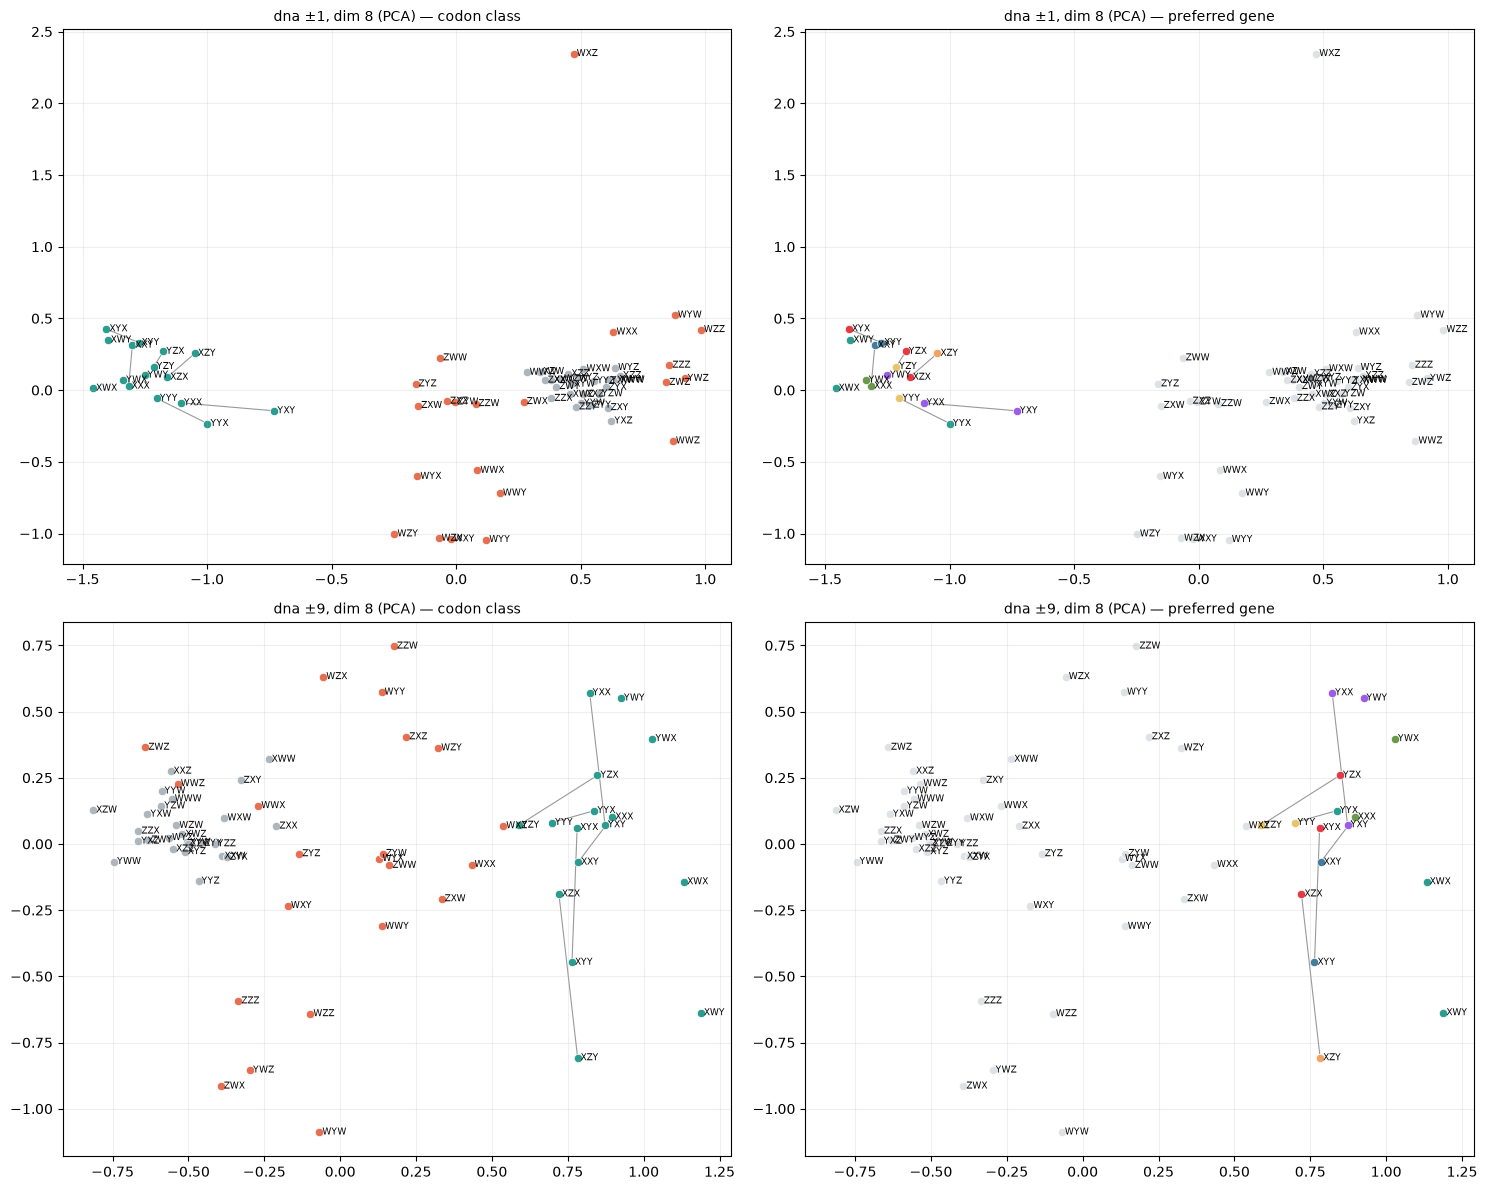

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for row, k in enumerate(HALF_WINDOWS):
    W = models[("dna", k, 8)]["W"]
    plot_embedding(W, vocabularies["dna"], f"dna ±{k}, dim 8 (PCA) — codon class", axes[row, 0], "class")
    plot_embedding(W, vocabularies["dna"], f"dna ±{k}, dim 8 (PCA) — preferred gene", axes[row, 1], "gene")
fig.tight_layout()
plt.show()

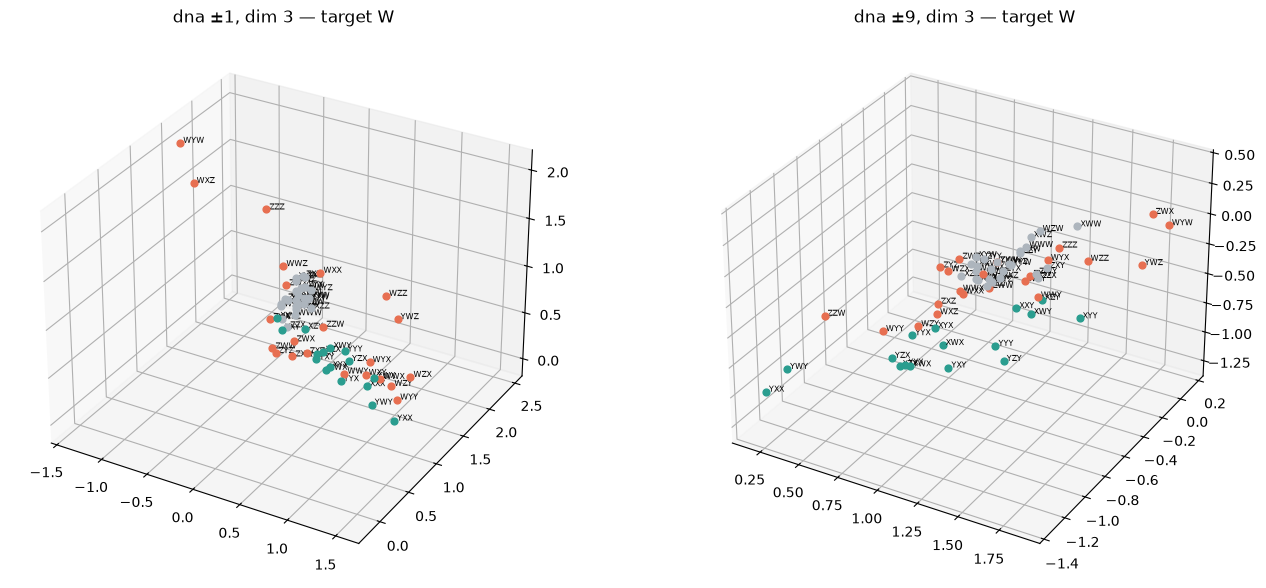

In [10]:
fig = plt.figure(figsize=(14, 6))
for i, k in enumerate(HALF_WINDOWS, start=1):
    W = models[("dna", k, 3)]["W"]
    ax = fig.add_subplot(1, 2, i, projection="3d")
    for codon, (x, y, z) in zip(vocabularies["dna"], W):
        ax.scatter(x, y, z, s=24, color=colour_of(codon, "class"))
        ax.text(x, y, z, f" {codon}", fontsize=6)
    ax.set_title(f"dna ±{k}, dim 3 — target W")
fig.tight_layout()
plt.show()

## Testing the predictions S1–S6

The criteria below were written into design-spec §7 **before** any of these models was trained. Each test
uses cosine similarity between target vectors $W$. Where a baseline is needed, it is the 95th percentile of
the same statistic over 1,000 random relabellings (permutations), so "holds" means "better than 95% of random
labellings".

The verdict uses dimension 8; dimensions 2 and 3 are reported alongside, because squeezing 64 codons into 2
numbers loses information.

In [11]:
def cosine_matrix(vectors):
    X = vectors / np.maximum(np.linalg.norm(vectors, axis=1, keepdims=True), 1e-12)
    return X @ X.T


def permutation_baseline(statistic, labels, rng, n=N_PERMUTATIONS):
    return float(np.percentile([statistic(rng.permutation(labels)) for _ in range(n)], 95))


def s1_coding_vs_spacer(W, vocabulary, rng):
    # Class purity of the 5 nearest neighbours, among coding and spacer-only codons only.
    codons = [c for c in vocabulary if c in L.CODE_TABLE or c in L.SPACER_ONLY_CODONS]
    idx = [vocabulary.index(c) for c in codons]
    cos = cosine_matrix(W[idx])
    np.fill_diagonal(cos, -np.inf)
    neighbours = np.argsort(-cos, axis=1)[:, :5]
    labels = np.array([L.codon_class(c) == "coding" for c in codons])
    purity = lambda lab: float(np.mean(lab[neighbours] == lab[:, None]))
    return purity(labels), permutation_baseline(purity, labels, rng)


def s2_preferred_gene(W, vocabulary, rng):
    # Fraction of coding codons whose nearest coding neighbour has the same preferred gene.
    codons = [c for c in L.CODING_CODONS if c in vocabulary]
    cos = cosine_matrix(W[[vocabulary.index(c) for c in codons]])
    np.fill_diagonal(cos, -np.inf)
    nearest = np.argmax(cos, axis=1)
    labels = np.array([L.preferred_gene(c) for c in codons])
    agreement = lambda lab: float(np.mean(lab[nearest] == lab))
    return agreement(labels), permutation_baseline(agreement, labels, rng)


def s3_register_vs_residue(W, vocabulary):
    # Mean cosine of same-register pairs with different residues, minus mean cosine of synonym pairs.
    cos = cosine_matrix(W)
    at = lambda a, b: cos[vocabulary.index(a), vocabulary.index(b)]
    same_register = [at(a, b) for a, b in combinations(L.CODING_CODONS, 2)
                     if a[2] == b[2] and L.CODE_TABLE[a] != L.CODE_TABLE[b]]
    synonyms = [at(a, b) for a, b in SYNONYM_PAIRS]
    return float(np.mean(same_register)), float(np.mean(synonyms))


def s4_initiator(W, vocabulary, n=5):
    cos = cosine_matrix(W)[vocabulary.index(L.INITIATOR)]
    order = [i for i in np.argsort(-cos) if vocabulary[i] != L.INITIATOR][:n]
    return [(vocabulary[i], float(cos[i])) for i in order]


PATHWAY_PAIRS = [(a, b) for a, b in zip(L.GENE_NAMES, L.GENE_NAMES[1:]) if (a, b) != ("NaxTAG", "NaxSNIP")]
MARKER_OF = {g["name"]: g["marker"] for g in L.GENES}
TERMINATOR_OF = {g["name"]: g["terminator"] for g in L.GENES}


def marker_rank(cos, vocabulary, codon, next_gene):
    # Rank (1 = most similar) of next_gene's marker among the 7 markers, seen from `codon`.
    sims = {g: cos[vocabulary.index(codon), vocabulary.index(m)] for g, m in MARKER_OF.items()}
    return 1 + sum(s > sims[next_gene] for s in sims.values())


def s5_pathway_order(W, vocabulary):
    # How many of the 5 non-leader adjacent pairs have terminator_i ranking marker_(i+1) first.
    cos = cosine_matrix(W)
    ranks = [int(marker_rank(cos, vocabulary, TERMINATOR_OF[a], b)) for a, b in PATHWAY_PAIRS]
    # Descriptive: the same test from each gene's most-preferred body codon.
    top_body = {g: max(L.CODING_CODONS, key=lambda c: L.codon_distribution(g)[c]) for g in L.GENE_NAMES}
    body_ranks = [int(marker_rank(cos, vocabulary, top_body[a], b)) for a, b in PATHWAY_PAIRS]
    return ranks, body_ranks


def s6_zv_twins(W, vocabulary, rng):
    # Mean cosine of Z/V twins vs random DNA-form/RNA-form pairings.
    dna_forms = [c for c in vocabulary if "Z" in c and L.transcribe(c) in vocabulary]
    rna_forms = [L.transcribe(c) for c in dna_forms]
    cos = cosine_matrix(W)
    block = cos[np.ix_([vocabulary.index(c) for c in dna_forms], [vocabulary.index(c) for c in rna_forms])]
    mean_pairing = lambda perm: float(np.mean(block[np.arange(len(perm)), perm]))
    identity = np.arange(len(dna_forms))
    return mean_pairing(identity), permutation_baseline(mean_pairing, identity, rng), len(dna_forms)

In [12]:
rows = []
rng = np.random.default_rng(SEED)
for (corpus, k, dim), m in models.items():
    W, vocab = m["W"], vocabularies[corpus]
    base = {"corpus": corpus, "half_window": k, "dim": dim}
    if corpus == "dna":
        v, b = s1_coding_vs_spacer(W, vocab, rng)
        rows.append({**base, "id": "S1", "metric": "5-NN class purity (coding vs spacer-only)", "value": v, "baseline": b, "holds": v > b})
        v, b = s2_preferred_gene(W, vocab, rng)
        rows.append({**base, "id": "S2", "metric": "nearest coding neighbour shares preferred gene", "value": v, "baseline": b, "holds": v > b})
        same_register, synonyms = s3_register_vs_residue(W, vocab)
        rows.append({**base, "id": "S3", "metric": "mean cos same register − mean cos synonyms", "value": same_register - synonyms,
                     "baseline": 0.0, "holds": same_register - synonyms > 0})
        neighbours = s4_initiator(W, vocab)
        rows.append({**base, "id": "S4", "metric": "WXZ nearest neighbours: " + ", ".join(f"{c} {s:.2f}" for c, s in neighbours),
                     "value": None, "baseline": None, "holds": None})
    if corpus in ("dna", "shuffled"):
        ranks, body_ranks = s5_pathway_order(W, vocab)
        firsts = sum(r == 1 for r in ranks)
        holds = firsts == 5 if corpus == "dna" else firsts <= 2
        rows.append({**base, "id": "S5", "metric": f"terminator→next marker ranked first (ranks {ranks}; body codons {body_ranks})",
                     "value": firsts, "baseline": 5 if corpus == "dna" else 2, "holds": holds})
    if corpus == "mixed":
        v, b, n = s6_zv_twins(W, vocab, rng)
        rows.append({**base, "id": "S6", "metric": f"mean cosine of {n} Z/V twins", "value": v, "baseline": b, "holds": v > b})

predictions = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120)
predictions.round(3)

,corpus,half_window,dim,id,metric,value,baseline,holds
0,dna,1,2,S1,5-NN class purity (coding vs spacer-only),1.000,0.600,True
1,dna,1,2,S2,nearest coding neighbour shares preferred gene,0.000,0.312,False
2,dna,1,2,S3,mean cos same register − mean cos synonyms,0.002,0.000,True
3,dna,1,2,S4,"WXZ nearest neighbours: ZWZ 1.00, XWZ 1.00, ZZX 1.00, YXZ 1.00, WXW 1.00",NaN,NaN,None
4,dna,1,2,S5,"terminator→next marker ranked first (ranks [3, 1, 4, 7, 6]; body codons [3, 1, 4, 7, 6])",1.000,5.000,False
5,dna,1,3,S1,5-NN class purity (coding vs spacer-only),1.000,0.586,True
6,dna,1,3,S2,nearest coding neighbour shares preferred gene,0.375,0.250,True
7,dna,1,3,S3,mean cos same register − mean cos synonyms,0.024,0.000,True
8,dna,1,3,S4,"WXZ nearest neighbours: WYW 0.99, ZZZ 0.93, ZXY 0.85, WWZ 0.85, ZWY 0.84",NaN,NaN,None
9,dna,1,3,S5,"terminator→next marker ranked first (ranks [1, 2, 7, 5, 6]; body codons [2, 3, 6, 3, 6])",1.000,5.000,False


### Verdicts (dimension 8)

S5's verdict needs both corpora: it holds only if the pathway corpus passes **and** the shuffled corpus
loses the signal. S4 holds by construction; its row is descriptive.

In [13]:
false_starts = pd.read_csv(f"{CORPUS_DIR}/genome.csv").query("codon == @L.INITIATOR")["start_role"].value_counts(normalize=True)
print("Share of WXZ occurrences by role (genome corpus):")
print(false_starts.round(3).to_string(), "\n")

verdicts = []
for pid in ["S1", "S2", "S3", "S6"]:
    for k in HALF_WINDOWS:
        r = predictions.query("id == @pid and dim == 8 and half_window == @k").iloc[0]
        verdicts.append({"id": pid, "half_window": f"±{k}", "corpus": r["corpus"], "value": round(r["value"], 3),
                         "baseline": round(r["baseline"], 3), "verdict": "holds" if r["holds"] else "fails"})
for k in HALF_WINDOWS:
    p = predictions.query("id == 'S5' and dim == 8 and half_window == @k")
    dna_r, shuf_r = p[p.corpus == "dna"].iloc[0], p[p.corpus == "shuffled"].iloc[0]
    verdicts.append({"id": "S5", "half_window": f"±{k}", "corpus": "dna / shuffled",
                     "value": f"{dna_r['value']} / {shuf_r['value']} of 5", "baseline": "5 / ≤2",
                     "verdict": "holds" if dna_r["holds"] and shuf_r["holds"] else "fails"})
verdicts.append({"id": "S4", "half_window": "all", "corpus": "dna", "value": "one vector per type",
                 "baseline": "—", "verdict": "holds by construction"})
verdicts = pd.DataFrame(verdicts).sort_values(["id", "half_window"]).reset_index(drop=True)
verdicts

Share of WXZ occurrences by role (genome corpus):
start_role
true_start                0.745
false_start_broken_rbs    0.137
false_start_spacer        0.118 



,id,half_window,corpus,value,baseline,verdict
0,S1,±1,dna,1.0,0.586,holds
1,S1,±9,dna,0.995,0.59,holds
2,S2,±1,dna,0.812,0.25,holds
3,S2,±9,dna,0.938,0.253,holds
4,S3,±1,dna,-0.007,0.0,fails
5,S3,±9,dna,-0.019,0.0,fails
6,S4,all,dna,one vector per type,—,holds by construction
7,S5,±1,dna / shuffled,0.0 / 0.0 of 5,5 / ≤2,fails
8,S5,±9,dna / shuffled,3.0 / 0.0 of 5,5 / ≤2,fails
9,S6,±1,mixed,0.41,0.3,holds


### What came out (seed 42)

**Hold (dimension 8, both half-windows):**

- **S1 — coding vs spacer-only.**
  - The 5-nearest-neighbour class purity is 1.00 at ±1 and 0.995 at ±9; the baseline is about 0.59.
  - Coding codons live inside gene bodies, so their contexts are other coding codons. Spacer codons are
    surrounded by random codons.
- **S2 — dialects.**
  - The nearest coding neighbour shares the preferred gene for 81% of coding codons at ±1 and 94% at ±9. The
    baseline is 25%.
  - The wider window sees more of the gene body, so it averages more dialect.
- **S6 — Z/V twins.**
  - In the mixed corpus, the 37 twins have a mean cosine of 0.41 at ±1 and 0.29 at ±9. The 95th percentile of
    random DNA/RNA pairings is 0.30 and 0.22.
  - The model never learns that `ZWX` and `VWX` are the same word. They come closer only because they share
    neighbours (codons without Z look the same in both alphabets). This is a weak convergence, not a
    merging.

**Fail:**

- **S3 — register vs residue.**
  - At dimension 8, same-register codons with different residues are *not* more similar than synonyms.
  - The mean cosine is 0.754 for same-register pairs and 0.760 for synonyms at ±1; at ±9 it is 0.694 and 0.713.
    The two effects are about the same size, and the residue effect is slightly larger.
  - At dimensions 2 and 3 the difference is slightly positive (see the table above), so the verdict depends on
    the dimension. That is a sign of a weak effect, not a robust one.
  - Why: a body codon's context is the mixture of the dialects of the genes that use it. Both synonyms of a
    residue are used by every gene that uses the residue; the register only shifts the split 80/20. Codons of
    the same register but different residues are often preferred by *different* genes. In this generator,
    style does not dominate meaning.
- **S5 — pathway order.**
  - At ±9 in the pathway corpus, terminator_i ranks the next gene's marker first in 3 of the 5 non-leader
    pairs (GATE→TAG, SNIP→FLIP, GRAB→PAY), and second in the other two (FLIP→GRAB, PAY→DUMP). The criterion
    asked for 5 of 5.
  - The control behaves as predicted: in the shuffled corpus, 0 of 5 rank first at ±9 (ranks 4–6), and at ±1
    the pathway corpus also gets 0 of 5.
  - So pathway adjacency is visible in the vectors — strongly against the shuffled control — but not cleanly
    enough to recover the full order from the cosines alone. The prediction as stated fails.
  - The body-codon ranks are in the table; they are reported descriptively, as specified.

**By construction:**

- **S4 — one vector for WXZ.**
  - 74.5% of `WXZ` occurrences are true starts, 13.7% are broken-RBS false starts and 11.8% are spacer
    decoys. All of them are blended into one vector.
  - At ±9 its nearest neighbour is `WXX`, the RBS codon. Telling a true start from a false start needs a vector
    per occurrence (Part B).

**Training caveat.**
- The ±9 losses are flat after the first epoch (each epoch has about 10 million samples).
- The ±1 losses are still decreasing slightly at epoch 5 (about −0.002 per epoch). Those runs are close to
  converged but not fully converged.
- The number of epochs was fixed before the predictions were computed, and it was not changed afterwards, so
  that it could not be tuned towards a result.

## Export for Lab A

`w2v-results.json` holds, for every configuration, $W$, $U$, the loss history and the cosine similarities of
$W$, plus the prediction table. Lab A uses it for its "Compare with notebook" and "Predictions" panels; the
lab recomputes the same metrics live for the student's own run.

In [14]:
def round_list(array, decimals):
    return np.round(np.asarray(array, dtype=float), decimals).tolist()


payload = {
    "metadata": {
        "produced_by": NOTEBOOK,
        "function": train_skipgram.__name__,
        "source": "\n\n".join(inspect.getsource(f) for f in (train_skipgram, build_positive_pairs, noise_distribution, add_rows)),
        "seed": SEED,
        "params": {"corpora": CORPORA, "half_windows": HALF_WINDOWS, "dimensions": DIMENSIONS},
        "generator_version": L.GENERATOR_VERSION,
        "created": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    },
    "vocabularies": {"dna": vocabularies["dna"], "mixed": vocabularies["mixed"]},
    "training": {"negatives": NEGATIVES, "learning_rate": LEARNING_RATE, "epochs": EPOCHS,
                 "batch_size": BATCH_SIZE, "init_std": INIT_STD, "noise_power": 0.75},
    "configs": [
        {"corpus": corpus, "half_window": k, "dim": dim, "seed": m["seed"],
         "W": round_list(m["W"], 6), "U": round_list(m["U"], 6),
         "loss_history": round_list(m["losses"], 6),
         "cosine": round_list(cosine_matrix(m["W"]), 4)}
        for (corpus, k, dim), m in models.items()
    ],
    "predictions": [
        {k: (None if isinstance(v, float) and np.isnan(v) else (v.item() if hasattr(v, "item") else v))
         for k, v in row.items()}
        for row in predictions.to_dict("records")
    ],
    "prediction_sources": {f.__name__: inspect.getsource(f) for f in
                           (s1_coding_vs_spacer, s2_preferred_gene, s3_register_vs_residue, s4_initiator,
                            s5_pathway_order, s6_zv_twins)},
}
with open(OUTPUT_FILE, "w", encoding="utf-8") as f:
    json.dump(payload, f, separators=(",", ":"))
print(f"Saved {OUTPUT_FILE} ({os.path.getsize(OUTPUT_FILE) / 1e6:.2f} MB)")

Saved ../data/web/w2v-results.json (0.89 MB)
